# Plotting weather maps

In this notebook we see how to plot spatial weather data on a map. In our dataset, column `geoLaenge` is the Latitute and `geoBreite` is the Longitude coordinate of a measurement. The column `TT_10` contains the measured air temperature at the position in degrees celsius. The column `RWS_10` (rainfall water sum over 10 minutes) contains precipitation in millimeter per square meter. 

In [1]:
import pandas as pd
import numpy as np
import stackview
from datetime import datetime
from dwd_weather import load_borders
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
rain_dataset = "rain_recent"
temp_dataset = "temp_recent"

selected_time_point = datetime(2026, 6, 30, 12, 00)

In [3]:
df = pd.read_parquet(temp_dataset + ".parquet")
df.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor,Stations_id,von_datum,bis_datum,Stationshoehe,geoBreite,geoLaenge,Stationsname,Bundesland,Abgabe,datetime
0,44,202412310000,3,-999.0,6.4,6.0,87.3,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:00:00
1,44,202412310010,3,-999.0,6.4,6.1,86.9,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:10:00
2,44,202412310020,3,-999.0,6.4,5.9,87.5,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:20:00
3,44,202412310030,3,-999.0,6.4,6.0,87.1,4.4,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:30:00
4,44,202412310040,3,-999.0,6.4,5.9,87.9,4.5,eor,00044,20070208,20260704,44,52.9336,8.237,Großenkneten,Niedersachsen,Frei,2024-12-31 00:40:00


In [4]:
# correction: The data contains -999 values, which seem to denote that these are missing data.
df["TT_10"] = df["TT_10"].replace(-999.0, np.nan)

In [5]:
timepoint = df[df["datetime"] == selected_time_point]
timepoint.head()

,STATIONS_ID,MESS_DATUM,QN,PP_10,TT_10,TM5_10,RF_10,TD_10,eor,Stations_id,von_datum,bis_datum,Stationshoehe,geoBreite,geoLaenge,Stationsname,Bundesland,Abgabe,datetime
78696,44,202606301200,3,-999.0,26.4,34.9,53.2,16.1,eor,00044,20070208,20260704,44,52.9336,8.2370,Großenkneten,Niedersachsen,Frei,2026-06-30 12:00:00
157896,73,202606301200,3,-999.0,29.7,33.6,47.4,17.3,eor,00073,20070214,20260704,374,48.6183,13.0620,Aldersbach-Kramersepp,Bayern,Frei,2026-06-30 12:00:00
237096,78,202606301200,3,-999.0,25.1,34.7,58.0,16.3,eor,00078,20041011,20260703,64,52.4853,7.9125,Alfhausen,Niedersachsen,Frei,2026-06-30 12:00:00
316296,91,202606301200,3,-999.0,26.1,28.9,49.8,14.8,eor,00091,20020820,20260704,304,50.7446,9.3450,Alsfeld-Eifa,Hessen,Frei,2026-06-30 12:00:00
395496,96,202606301200,3,1017.1,26.9,30.9,27.3,6.5,eor,00096,20190409,20260704,50,52.9437,12.8518,Neuruppin-Alt Ruppin,Brandenburg,Frei,2026-06-30 12:00:00


In [6]:
timepoint.shape

(467, 19)

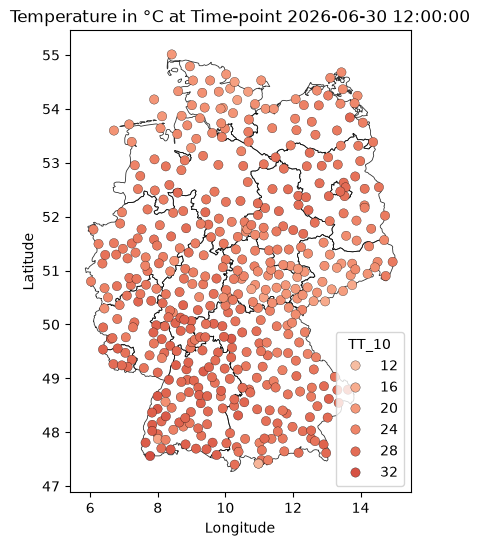

In [7]:
def plot(df, selected_time_point, column="TT_10", label="Temperature in °C", min_value=-40, max_value=40, colormap="coolwarm"):
    borders_gdf = load_borders()
    
    # Plot
    fig, ax = plt.subplots(figsize=(5, 6))
    
    # Add German federal state borders
    borders_gdf.boundary.plot(
        ax=ax,
        color="black",
        linewidth=0.6,
        alpha=0.8,
        zorder=1
    )
    
    # Add measurement points
    scatter = sns.scatterplot(
        data=timepoint,
        x="geoLaenge",
        y="geoBreite",
        hue=column,
        palette=colormap,
        ax=ax,
        hue_norm=(min_value, max_value),
        s=45,
        edgecolor="black",
        linewidth=0.2,
        zorder=2
    )
    
    ax.set_title(f"{label} at Time-point {selected_time_point}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    
    plt.show()
plot(timepoint, selected_time_point)

We can also plot this for another timepoint.

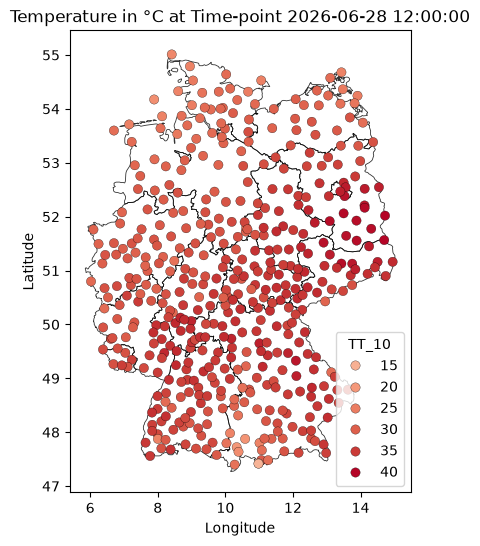

In [8]:
selected_time_point = datetime(2026, 6, 28, 12, 00)

timepoint = df[df["datetime"] == selected_time_point]
plot(timepoint, selected_time_point)

And we can plot a similar dataset, e.g. for rainfall.

In [9]:
df2 = pd.read_parquet(rain_dataset + ".parquet")
df2["RWS_10"] = df2["RWS_10"].replace(-999.0, np.nan)

In [10]:
selected_time_point = datetime(2026, 6, 29, 7, 0)

timepoint = df2[df2["datetime"] == selected_time_point]

When plotting rainfall data, we need to modify min/max values as precipitation is given in millimetres per square meter.

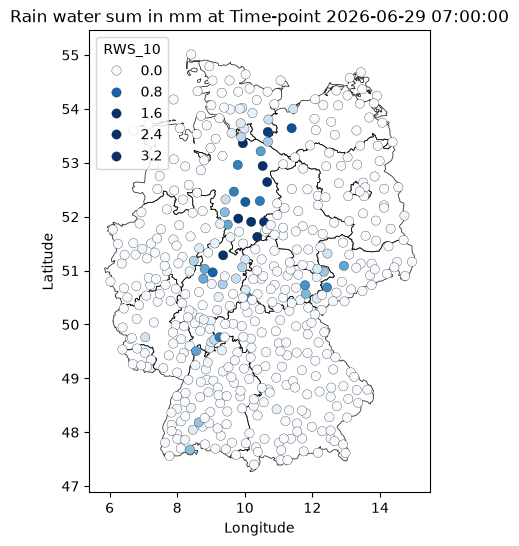

In [11]:
plot(timepoint, selected_time_point, column="RWS_10", label="Rain water sum in mm", min_value=0, max_value=1, colormap="Blues")